# Module V: Transfer learning
An ImageNet-pretrained **ResNet18** (first layer adapted to 1-channel input) replaces the small CNN and is fine-tuned together with the LSTM and ghost decoder. We compare it with the same architecture using a CNN trained from scratch.

In [1]:
import sys, json, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import numpy as np, matplotlib.pyplot as plt, inspect
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
res = lambda m: json.load(open(ROOT / "runs" / m / "results.json"))
from src.models.nets import ResNetEncoder
print(inspect.getsource(ResNetEncoder))

class ResNetEncoder(nn.Module):
    """ImageNet-pretrained ResNet18 adapted to 1-channel 64x64 input. Module V (transfer learning)."""
    out_dim = 512

    def __init__(self, pretrained: bool = True):
        super().__init__()
        import torchvision

        weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        net = torchvision.models.resnet18(weights=weights)
        w = net.conv1.weight.data.sum(1, keepdim=True)          # RGB -> 1 channel, keeps pretrained filters
        net.conv1 = nn.Conv2d(1, 64, 7, 2, 3, bias=False)
        net.conv1.weight.data = w
        net.maxpool = nn.Identity()                              # keep resolution at 64x64
        net.fc = nn.Identity()
        self.net = net

    def forward(self, x):
        return self.net(x)



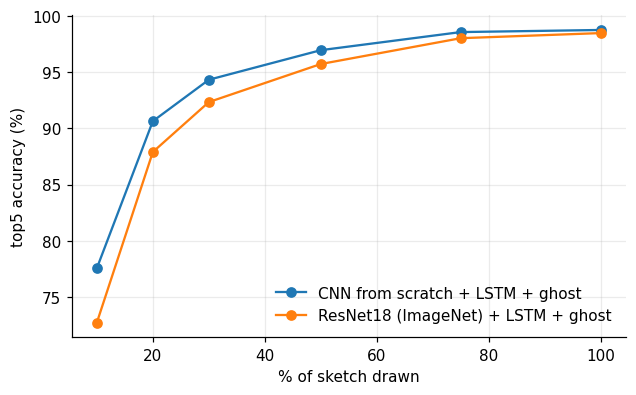

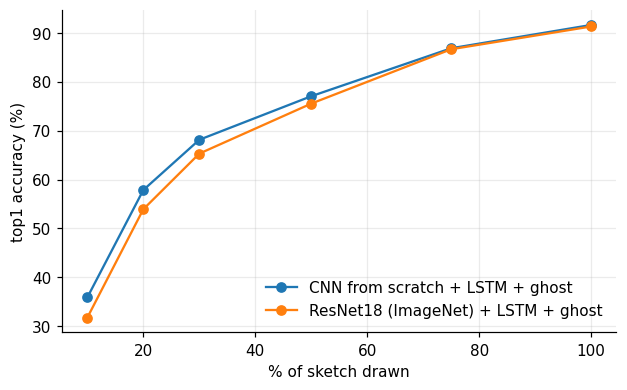

In [2]:
def curve(models, metric="top5"):
    fig, ax = plt.subplots(figsize=(6.5, 3.8))
    for m, label in models.items():
        r = res(m); xs = sorted(r, key=float)
        ax.plot([float(x) * 100 for x in xs], [r[x][metric] * 100 for x in xs], marker="o", label=label)
    ax.set(xlabel="% of sketch drawn", ylabel=f"{metric} accuracy (%)"); ax.grid(alpha=.25); ax.legend(frameon=False); plt.show()
curve({'fusion_ghost': 'CNN from scratch + LSTM + ghost', 'resnet_ghost': 'ResNet18 (ImageNet) + LSTM + ghost'})
curve({'fusion_ghost': 'CNN from scratch + LSTM + ghost', 'resnet_ghost': 'ResNet18 (ImageNet) + LSTM + ghost'}, 'top1')

In [3]:
import csv
for m in ['fusion_ghost', 'resnet_ghost']:
    rows = list(csv.DictReader(open(ROOT / 'runs' / m / 'log.csv')))
    print(f"{m}: {len(rows)} epochs, ~{np.mean([float(r['secs']) for r in rows]):.0f} s/epoch on the Kaggle GPU, best val mean top-1 {max(float(r['val_mean_top1']) for r in rows):.3f}")

fusion_ghost: 20 epochs, ~55 s/epoch on the Kaggle GPU, best val mean top-1 0.691
resnet_ghost: 12 epochs, ~130 s/epoch on the Kaggle GPU, best val mean top-1 0.670


## Finding
Transfer learning did **not** beat the small CNN trained from scratch here: line drawings are far from ImageNet photographs, and the larger network costs more time per epoch. This is a genuine negative result and is reported as such.